# Practical 3 - Understand Descriptive Stats

This one uses the same Teaching Ratings dataset as before. This time I'm looking at tenure, minority status, age, gender and evaluation scores, and answering 5 questions about them.

First, the usual imports and loading the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("TeachingRatings.csv")
df.head()

,rownames,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,1,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,2,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,3,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,4,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,5,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5


### Q1. Percentage of visible minorities who are tenured, and does tenure status differ by minority status?

I'm grouping by the "minority" column (yes/no) and looking at what percentage in each group are tenured vs not.

In [2]:
tenure_by_minority = pd.crosstab(df["minority"], df["tenure"], normalize="index") * 100
tenure_by_minority = tenure_by_minority.round(2)
print(tenure_by_minority)

tenure       no    yes
minority              
no        23.06  76.94
yes       15.62  84.38


**Answer:** About 84.4% of visible-minority instructors are tenured, compared to about 76.9% of non-minority instructors. So tenure rate is actually a bit *higher* among visible minorities in this dataset — around 7-8 percentage points higher. It does differ, just not in a way that suggests a disadvantage here; if anything it's the opposite direction of what you might expect. That said, the minority group is much smaller in this dataset, so this difference should be read with a bit of caution.

### Q2. Does average age differ by tenure? Means and standard deviations for both groups

Grouping by tenure status and getting the mean and standard deviation of age for each group.

In [3]:
age_by_tenure = df.groupby("tenure")["age"].agg(["mean", "std"]).round(2)
print(age_by_tenure)

         mean    std
tenure              
no      50.19   6.95
yes     47.85  10.42


**Answer:** Tenured professors average about 47.9 years old (std dev 10.4), while non-tenured professors average about 50.2 years old (std dev 6.9). Interestingly, tenured professors are on average *slightly younger* here, though the difference (~2.3 years) is small. Non-tenured professors also have a tighter spread in age (lower std dev), while tenured professors range more widely in age.

### Q3. Which graph works better for the age variable, and plot it

Age is a continuous numeric variable, so a **histogram** is the better choice here — it groups values into bins and shows how age is distributed across all professors. A bar chart wouldn't work well since age isn't a small set of categories, it's a continuous range of values.

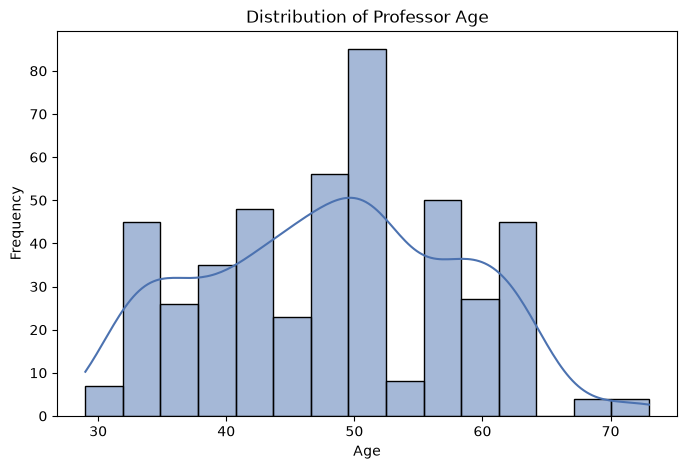

In [4]:
plt.figure(figsize=(8,5))
sns.histplot(df["age"], bins=15, kde=True, color="#4C72B0", edgecolor="black")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Distribution of Professor Age")
plt.show()

The age distribution looks roughly bell-shaped, centered somewhere in the mid-to-late 40s, with most professors falling between about 40 and 60 years old, and fewer at the very young or very old ends.

### Q4. Difference between plt.bar and plt.barh, and plot the gender variable

`plt.bar()` draws **vertical** bars — categories sit along the x-axis and bar height (going up) shows the value. `plt.barh()` draws **horizontal** bars instead — categories sit along the y-axis and bar length (going sideways) shows the value. They show the exact same information, just rotated; `barh` is often used when category names are long and wouldn't fit well under vertical bars.

Since gender is a simple category (male/female), I'll plot the count of each using a bar chart.

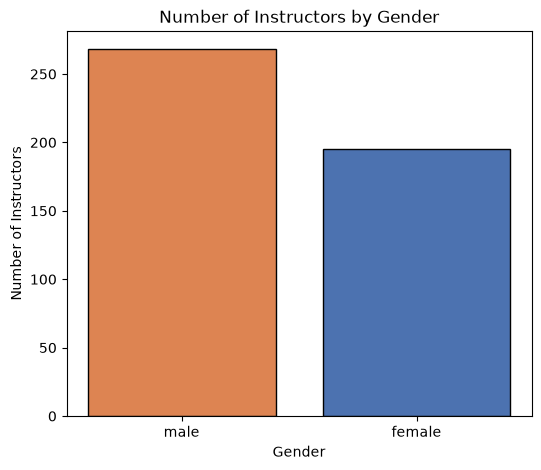

In [5]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(6,5))
plt.bar(gender_counts.index, gender_counts.values, color=["#DD8452", "#4C72B0"], edgecolor="black")
plt.xlabel("Gender")
plt.ylabel("Number of Instructors")
plt.title("Number of Instructors by Gender")
plt.show()

### Q5. Median evaluation score for tenured professors

Filtering to just the tenured professors and finding the median of their "eval" scores.

In [6]:
median_eval_tenured = df[df["tenure"] == "yes"]["eval"].median()
print("Median evaluation score for tenured professors:", median_eval_tenured)

Median evaluation score for tenured professors: 4.0


**Answer:** The median evaluation score for tenured professors is **4.0** (out of 5).

## Conclusion

Working through this dataset, a few things stood out. Tenure doesn't seem to disadvantage visible-minority instructors here — in fact their tenure rate was a bit higher than non-minority instructors, though the minority group is smaller so this comparison isn't super strong. Age and tenure also showed a small relationship, with tenured professors being slightly younger on average, though the difference wasn't dramatic. For visualizing age (a continuous variable) a histogram was clearly the right tool, while a simple bar chart worked fine for something categorical like gender counts. Lastly, tenured professors have a solid median evaluation score of 4 out of 5, suggesting tenure status isn't linked to noticeably weaker teaching ratings in this dataset.